# Figure 5: reconstruction quality over the holdout

Section 4.4, `fig:recon_hist`. The distributions of deterministic
reconstruction quality at the encoder mean over the held-out set: the
area-adjusted structural similarity between input and reconstruction,
and the root-mean-square error of the real coefficient vector in units
of normalised intensity.

Whole-sphere, with the render grid stated alongside the SSIM. Every
surface in the holdout is scored, not the 5000 the posterior run used:
at 5000 the RMSE histogram carries Poisson wiggles of a few counts per
bin that read as structure, and the full set removes them. The pass is
cached, so re-running this notebook is immediate.

## Imports

In [1]:
from _setup import *

from starspot_sbi.pipeline import decode_ceiling_coeffs

## Setup

The whole holdout, in chunks, and the cache the pass writes.

In [2]:
DEVICE = 'cuda'
CHUNK = 2000               # surfaces held in memory at once
CACHE = os.path.join(CACHES, 'fig05_recon.npz')

## Selecting the sample

Every surface in the holdout index.

In [3]:
idx = load_meta().index.values
n_spots = load_meta().loc[idx, 'n_spots'].values
print(f'{len(idx):,} holdout surfaces, the whole set, '
      f'spot counts {n_spots.min()} to {n_spots.max()}')

100,000 holdout surfaces, the whole set, spot counts 1 to 11


## Inference

Reconstructs every surface at the encoder mean and scores it in both
the pixel and the coefficient domain, one chunk in memory at a time:
the holdout is 100,000 surfaces, and the renders alone would not fit
otherwise. The truth RMS of the non-DC coefficients is accumulated in
the same pass, since the draft relates the RMSE to it.

In [4]:
def score_all():
    """Reconstruct and score the whole holdout, chunk by chunk."""
    vae, stats = load_autoencoder(device=DEVICE)
    ssim = np.empty(len(idx))
    rmse = np.empty(len(idx))
    sq = n_sq = 0.0
    for a in range(0, len(idx), CHUNK):
        b = min(a + CHUNK, len(idx))
        coeffs = np.stack([np.load(os.path.join(HOLDOUT, 'surfaces',
                                                f'surface_{i:07d}.npy'))
                           for i in idx[a:b]])
        truth_real = np.stack([coeffs_to_real(c) for c in coeffs])
        rec = decode_ceiling_coeffs(coeffs, vae, stats, device=DEVICE)
        timgs = render_draws(truth_real, device=DEVICE)
        rimgs = render_draws(rec, device=DEVICE)
        ssim[a:b] = [metrics.ssim_aa_full(timgs[k], rimgs[k])
                     for k in range(b - a)]
        rmse[a:b] = np.sqrt(((truth_real - rec) ** 2).mean(axis=1))
        sq += (truth_real[:, 1:] ** 2).sum()
        n_sq += truth_real[:, 1:].size
        print(f'  {b:,} / {len(idx):,}', flush=True)
    return dict(idx=idx, ssim=ssim, rmse_coeff=rmse,
                amp=np.sqrt(sq / n_sq))


os.makedirs(CACHES, exist_ok=True)
z = np.load(CACHE) if os.path.exists(CACHE) else None
# the guard checks the scored population, not just that a file is there, so a
# different holdout or sample size recomputes instead of being silently reused
if z is not None and z['ssim'].size == len(idx) and np.array_equal(z['idx'],
                                                                   idx):
    d = {k: z[k] for k in z.files}
    print(f'scores read from {os.path.relpath(CACHE, REPO)}')
else:
    d = score_all()                 # the whole holdout; tens of minutes
    np.savez(CACHE, **d)
    print(f'scores written to {os.path.relpath(CACHE, REPO)}')

ssim, rmse_coeff, amp = d['ssim'], d['rmse_coeff'], float(d['amp'])
print(f'median ssim {np.median(ssim):.4f}, median coefficient RMSE '
      f'{np.median(rmse_coeff):.2e} over {ssim.size:,} surfaces')

/home/conaire/miniconda3/envs/paper2_gpu/lib/python3.12/site-packages/torch/nn/modules/transformer.py:385: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(


  2,000 / 100,000
  4,000 / 100,000
  6,000 / 100,000
  8,000 / 100,000
  10,000 / 100,000
  12,000 / 100,000
  14,000 / 100,000
  16,000 / 100,000
  18,000 / 100,000
  20,000 / 100,000
  22,000 / 100,000
  24,000 / 100,000
  26,000 / 100,000
  28,000 / 100,000
  30,000 / 100,000
  32,000 / 100,000
  34,000 / 100,000
  36,000 / 100,000
  38,000 / 100,000
  40,000 / 100,000
  42,000 / 100,000
  44,000 / 100,000
  46,000 / 100,000
  48,000 / 100,000
  50,000 / 100,000
  52,000 / 100,000
  54,000 / 100,000
  56,000 / 100,000
  58,000 / 100,000
  60,000 / 100,000
  62,000 / 100,000
  64,000 / 100,000
  66,000 / 100,000
  68,000 / 100,000
  70,000 / 100,000
  72,000 / 100,000
  74,000 / 100,000
  76,000 / 100,000
  78,000 / 100,000
  80,000 / 100,000
  82,000 / 100,000
  84,000 / 100,000
  86,000 / 100,000
  88,000 / 100,000
  90,000 / 100,000
  92,000 / 100,000
  94,000 / 100,000
  96,000 / 100,000
  98,000 / 100,000
  100,000 / 100,000
scores written to caches/fig05_recon.npz
median ssim 

## Plotting

Draws the figure from the names bound above.

Text(0, 0.5, 'Surfaces')

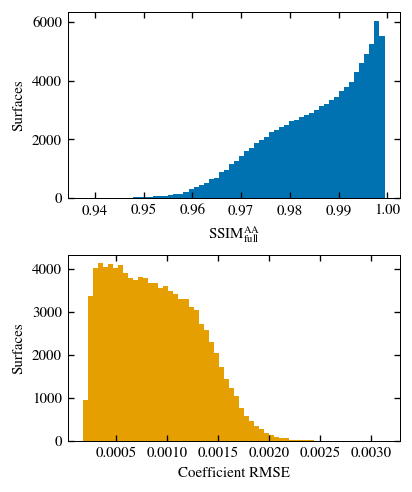

In [5]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(COL, COL * 1.2))
ax1.hist(ssim, bins=60, color=BLUE)
ax1.set_xlabel(r'${\rm SSIM}^{\rm AA}_{\rm full}$')
ax1.set_ylabel('Surfaces')
ax2.hist(rmse_coeff, bins=60, color=ORANGE)
ax2.set_xlabel('Coefficient RMSE')
ax2.set_ylabel('Surfaces')


## Saving and caption numbers

Writes the pdf and png, then prints the numbers the Section 4.4 text
quotes.

In [6]:
save_fig(fig, 'fig05_recon_hist')
print(f'render grid {GRID[0]} x {GRID[1]}, whole-sphere area weighting')
print(f'ssim_aa_full: median {np.median(ssim):.4f}, '
      f'5th percentile {np.percentile(ssim, 5):.4f}, '
      f'1st percentile {np.percentile(ssim, 1):.4f}, '
      f'minimum {ssim.min():.4f}')
print(f'coefficient RMSE: median {np.median(rmse_coeff):.2e}, '
      f'5th {np.percentile(rmse_coeff, 5):.2e}, '
      f'95th {np.percentile(rmse_coeff, 95):.2e}')
print(f'truth RMS amplitude of the non-DC coefficients: {amp:.2e}; '
      f'the median RMSE is '
      f'{np.median(rmse_coeff) / amp * 100:.0f} per cent of it')

wrote notebooks/paper/figs/fig05_recon_hist.pdf, notebooks/paper/figs/fig05_recon_hist.png
render grid 120 x 240, whole-sphere area weighting
ssim_aa_full: median 0.9876, 5th percentile 0.9667, 1st percentile 0.9594, minimum 0.9376
coefficient RMSE: median 8.44e-04, 5th 2.80e-04, 95th 1.62e-03
truth RMS amplitude of the non-DC coefficients: 4.13e-03; the median RMSE is 20 per cent of it
